> This walkthrough is adapted from the [GMM-MI walkthrough notebook](https://github.com/dpiras/GMM-MI/blob/main/notebooks/walkthrough_and_pitfalls.ipynb) by **Davide Piras**, which was imported into this repository together with its original commit history (see the git log of this file). The structure, scenarios and much of the text follow his original; the code and all numerical results are from `gmm-mi-torch`.

In this notebook, we show a simple walkthrough on how to use `gmm-mi-torch` to calculate MI on your data. We also cover different scenarios and pitfalls that might arise, explaining how to deal with each different case.

# Walkthrough

### First, we import all needed packages, and create some mock data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from gmm_mi_torch import estimate
from gmm_mi_torch.plotting import (plot_gmm_contours, plot_contours,
                                   create_heatmap, annotate_heatmap,
                                   histogram_estimates,
                                   plot_bias_chi2_histogram)


def analytic_MI_gaussian(cov):
    """Analytic MI (in nats) of a bivariate Gaussian with covariance `cov`."""
    rho = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    return -0.5 * np.log(1 - rho**2)

In [2]:
# create simple mock bivariate Gaussian data
N = int(1e4)
mean, cov = np.array([0, 0]), np.array([[1, 0.6], [0.6, 1]])
rng = np.random.default_rng(0)
X = rng.multivariate_normal(mean, cov, N)  # has shape (N, 2)
# recall that we have an analytic expression for MI in this simple case
analytic_MI = analytic_MI_gaussian(cov)
print(f'Analytic MI value is: {analytic_MI:.3f} nat')

Analytic MI value is: 0.223 nat


### At this point, we need to set the hyperparameters.
Everything goes through a single function, `estimate(X, quantity, ...)`. Its keyword arguments fall into the same three groups that GMM-MI configures through its parameter-holder classes: the parameters of every individual GMM fit, the parameters controlling how the number of components is chosen, and the parameters of the MI-distribution estimation. The next cell spells out all three groups with their default values - edit any line and re-run.

On top of these there are the torch-specific knobs - `device` (`'cpu'` or `'cuda'`), `dtype`, and the chunk sizes `em_chunk`/`mc_chunk`/`n_chunk` that trade memory against speed (see the README) - and `return_k=True`/`return_fit=True` to also return the selected number of components and the fitted model (used for the plots below). The full reference for every keyword lives in the docstring: run `help(estimate)`.

To see `gmm-mi-torch` in action, just run the next cell!

In [3]:
# parameters of every individual GMM fit (cross-validation and bootstrap alike)
fit_params = dict(init_type='random_responsibilities',  # or 'minmax', 'kmeans',
                                                        # 'randomized_kmeans' (with scale=...)
                  threshold_fit=1e-5,   # log-likelihood improvement threshold per fit
                  reg_covar=1e-6,       # covariance regularization
                  max_iter=500)         # maximum EM iterations per fit

# parameters to choose the number of GMM components
select_params = dict(protocol='batched',        # 'sequential' reproduces GMM-MI's search
                     n_inits=3,                 # independent initializations
                     n_folds=2,                 # cross-validation folds
                     metric_method='valid',     # or 'aic' / 'bic' (batched protocol)
                     threshold_components=1e-5, # metric improvement needed to keep adding k
                     max_components=20)         # or: fixed_components_number=<k>

# parameters for the MI distribution estimation
mi_dist_params = dict(n_bootstrap=50,       # bootstrap realizations (errorbar)
                      mc_samples=100_000)   # Monte Carlo samples for the integral

MI_mean, MI_std = estimate(X, 'MI', **fit_params, **select_params, **mi_dist_params)
print(f'Estimated MI: {MI_mean:.3f} \\pm {MI_std:.3f} nat')

Estimated MI: 0.222 \pm 0.006 nat


Note the units are in nats. Since the values above are exactly the defaults, the same result comes from simply calling `estimate(X, 'MI')`. The results are well in agreement with the ground truth - hooray! But what if something goes wrong?

### KL divergence

Since the estimator performs a fit of the joint distribution `p(x, y)`, it can be also used to estimate the [Kullback-Leibler](https://en.wikipedia.org/wiki/Kullback%E2%80%93Leibler_divergence) (KL) divergence between the marginals `p(x)` and `p(y)`, in both directions (KL is not symmetric, so the direction has to be specified). In particular, `'KL_forward'` calculates the KL between `p(x)` and `p(y)`, while `'KL_reverse'` calculates the KL between `p(y)` and `p(x)`. This can be simply done in the following way.

In [4]:
KL_mean, KL_std = estimate(X, 'KL_forward')
print(f'Estimated forward KL: {KL_mean:.4f} \\pm {KL_std:.4f} nat')
KL_mean, KL_std = estimate(X, 'KL_reverse')
print(f'Estimated reverse KL: {KL_mean:.4f} \\pm {KL_std:.4f} nat')

Estimated forward KL: 0.0002 \pm 0.0003 nat


Estimated reverse KL: 0.0002 \pm 0.0003 nat


In this case, the marginals are Gaussians with zero mean and unit variance, so both their forward and reverse KL divergence must be 0 - and they are, within the errors.

# Common scenarios

For example, consider the following scenario. Let's consider a much more complicated dataset: a Gaussian mixture model made of 5 components, the D5' synthetic dataset from GMM-MI (not shown in the paper, but analysed [here](https://github.com/dpiras/GMM-MI/blob/main/notebooks/synthetic_GMMs/4_MI_D5p_significance.ipynb)). Let's first show how `gmm-mi-torch` can successfully work on this dataset as well.

In [5]:
# the D5' synthetic dataset from GMM-MI: parameters copied from
# gmm_mi/data/synthetic_data.py; the true MI value ships with GMM-MI
# (notebooks/synthetic_GMMs/MI_synthetic_datasets/MI_D5p.npy)
true_MI = 0.17976205
true_weights = np.array([0.2, 0.35, 0.15, 0.12, 0.18])
true_means = np.array([[-1, 1], [0, 2], [-1.5, 2], [3, 1], [-0.25, 0]])
true_covariances = np.array([[[1, 0], [0, 0.1]],
                             [[0.5, 0.2], [0.2, 0.5]],
                             [[0.1, 0.05], [0.05, 0.1]],
                             [[0.5, -0.1], [-0.1, 0.9]],
                             [[0.2, -0.05], [-0.05, 0.1]]])
print(f'True MI: {true_MI:.3f} nat')


def sample_gmm(N, weights, means, covariances, seed):
    """Draw N samples from a GMM with the given parameters."""
    rng = np.random.default_rng(seed)
    counts = rng.multinomial(int(N), weights)
    X = np.concatenate([rng.multivariate_normal(m, c, n)
                        for m, c, n in zip(means, covariances, counts)])
    rng.shuffle(X)
    return X


X = sample_gmm(1e4, true_weights, true_means, true_covariances, seed=13)

True MI: 0.180 nat


In [6]:
# the sequential protocol mirrors GMM-MI's component search
MI_mean, MI_std, k, fit = estimate(X, 'MI', protocol='sequential',
                                   max_components=50,
                                   return_k=True, return_fit=True)
print(f'Estimated MI: {MI_mean:.3f} \\pm {MI_std:.3f} nat (k={k})')

Estimated MI: 0.179 \pm 0.005 nat (k=5)


Again, all good: the estimator returns a value of MI which is well within 1 standard deviation of the ground truth, and finds the correct number of components. Let's visualize the dataset and the fitted model, too.

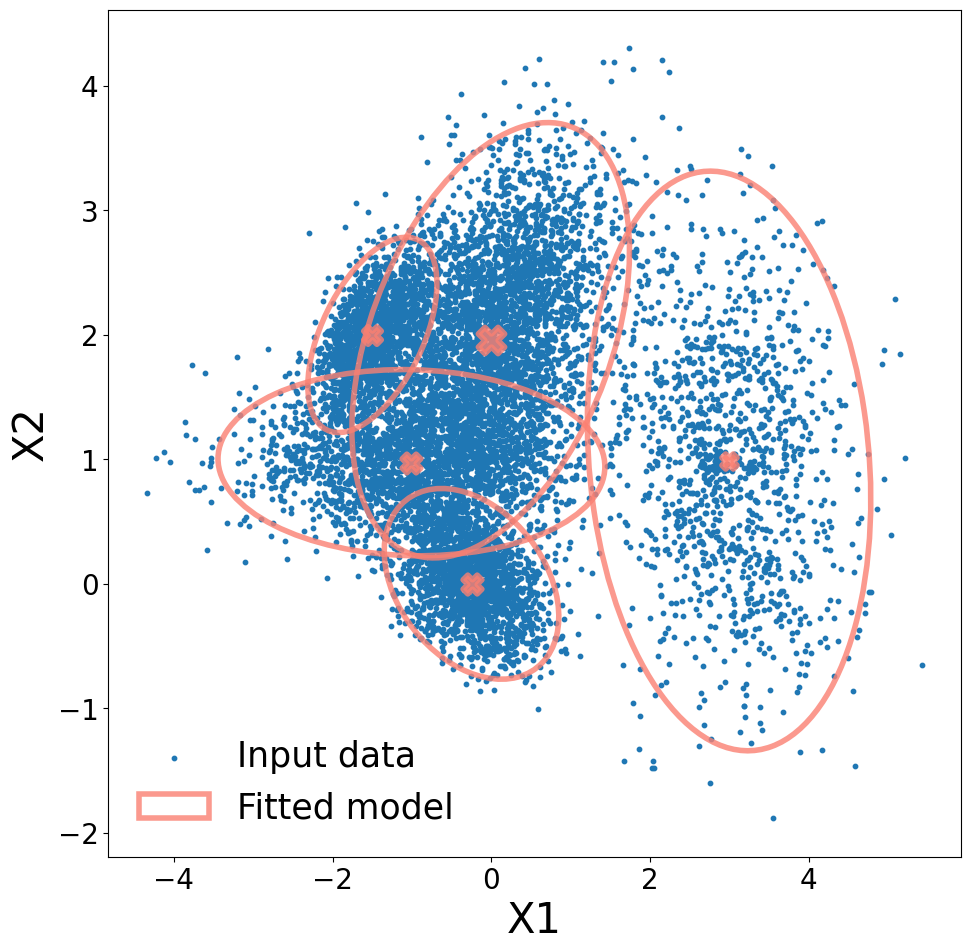

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

We can also plot the contours of the two distributions, using the original samples and samples from the fitted GMM. This becomes particularly useful when computing the conditional MI (see below), namely when we have a higher-dimensional distribution being fitted, as it becomes harder to visualise the individual GMM components in higher dimensions.

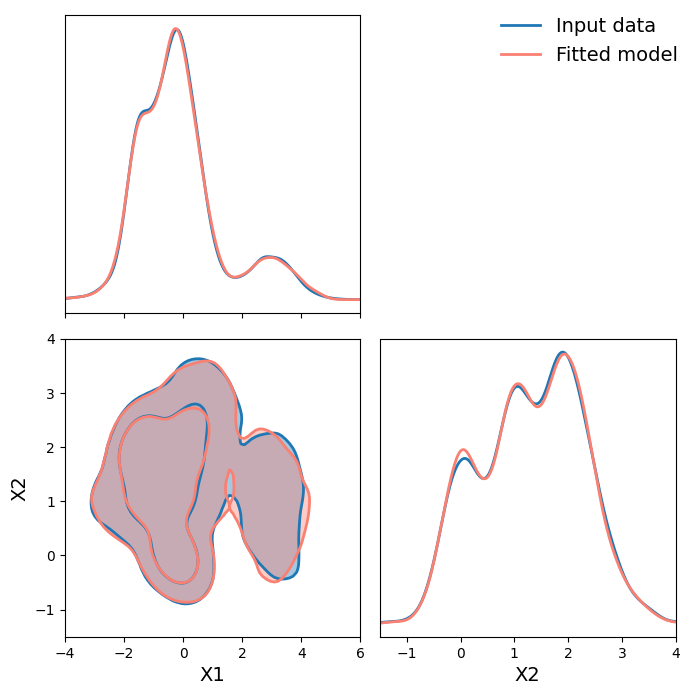

In [8]:
fig = plot_contours(X, fit.sample(len(X)), parameters=['X1', 'X2'],
                    extents={'X1': (-4, 6), 'X2': (-1.5, 4)})

## The fit does not seem to capture the data distribution

However, you might need a faster answer, so you decide you want to be less conservative in the choice of some hyperparameters. For example, you relax the `threshold_fit` from 1e-5 to 1e-3 (leaving everything else unchanged).

In [9]:
MI_mean, MI_std, k, fit = estimate(X, 'MI', protocol='sequential',
                                   max_components=50, threshold_fit=1e-3,
                                   return_k=True, return_fit=True)
print(f'Estimated MI: {MI_mean:.3f} \\pm {MI_std:.3f} nat (k={k})')

Estimated MI: 0.021 \pm 0.008 nat (k=2)


As you can see, the fitter in this case stops at 2 GMM components, and returns a heavily biased estimate of MI. You can check how the best fitted model looks on top of your data:

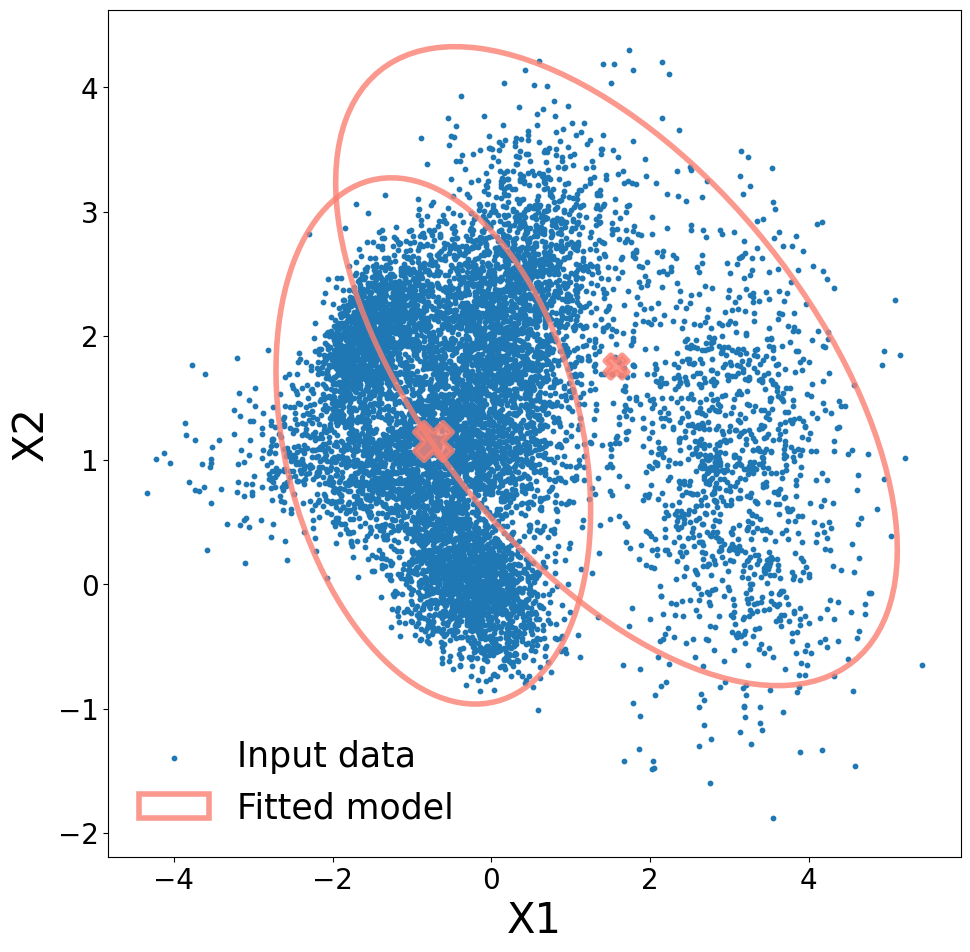

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

The fit is not terrible, but it leaves out some important features of the point cloud. We recommend always looking at the fitted model on top of your data in order not to bias your MI estimates, and lower `threshold_fit` if it does not look right. Another possibility is that your fit is stuck in a local optimum: in that case, make sure that you have set enough `n_inits`.

Alternatively, you can try and see if with a different initialization type the fitter is able to capture your data distribution. In this case, we try with the $k$-means initialization, still keeping the threshold to 1e-3.

In [11]:
MI_mean, MI_std, k, fit = estimate(X, 'MI', protocol='sequential',
                                   max_components=50, threshold_fit=1e-3,
                                   init_type='kmeans',
                                   return_k=True, return_fit=True)
print(f'Estimated MI: {MI_mean:.3f} \\pm {MI_std:.3f} nat (k={k})')

Estimated MI: 0.181 \pm 0.005 nat (k=5)


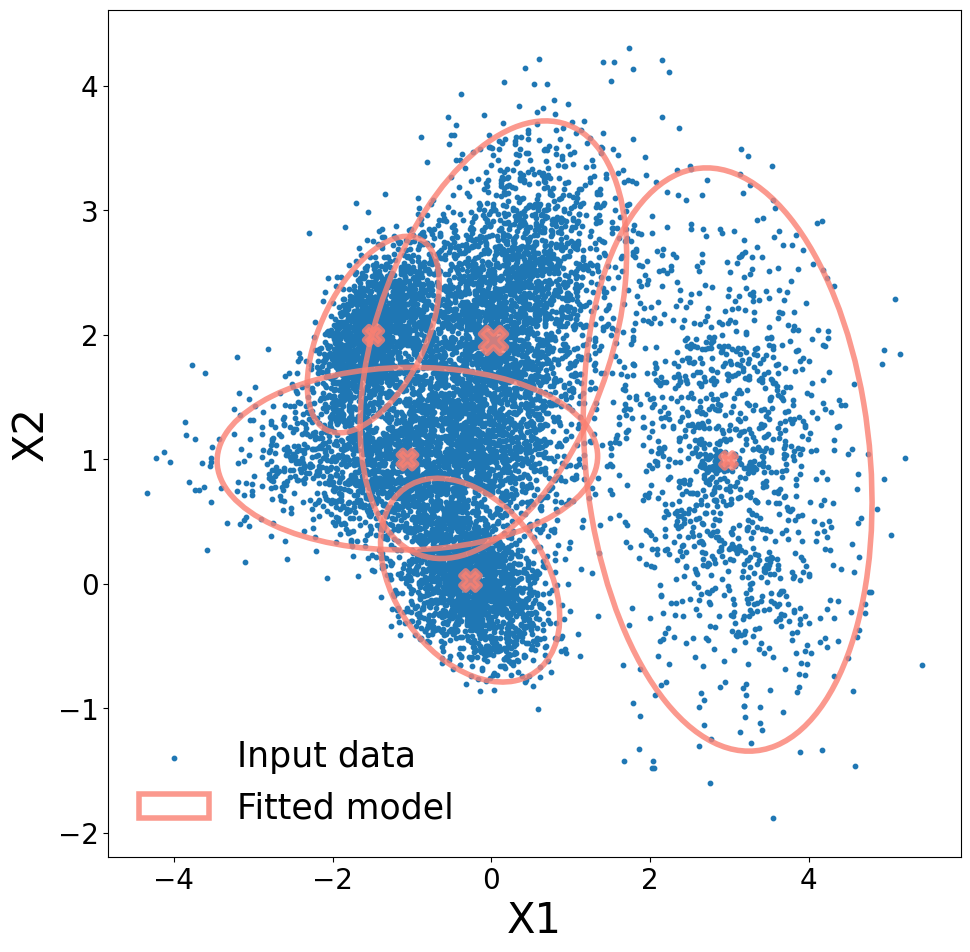

In [12]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

With a different initialization, the fitter was able to find the correct number of GMM components, and returned a consistent value of MI. However, there is no guarantee that the $k$-means initialization is better than the others (we will see this in a minute below), so always check the fitted model contours on top of your data.

A similar result can be obtained with the random initialization, but by changing the metric that is tracked to select the number of components. For instance, we can use the Akaike information criterion [AIC](https://en.wikipedia.org/wiki/Akaike_information_criterion); with `gmm-mi-torch`, the information criteria are available through the batched protocol.

In [13]:
MI_mean, MI_std, k, fit = estimate(X, 'MI', protocol='batched',
                                   max_components=10, threshold_fit=1e-3,
                                   metric_method='aic',
                                   return_k=True, return_fit=True)
print(f'Estimated MI: {MI_mean:.3f} \\pm {MI_std:.3f} nat (k={k})')

Estimated MI: 0.180 \pm 0.005 nat (k=7)


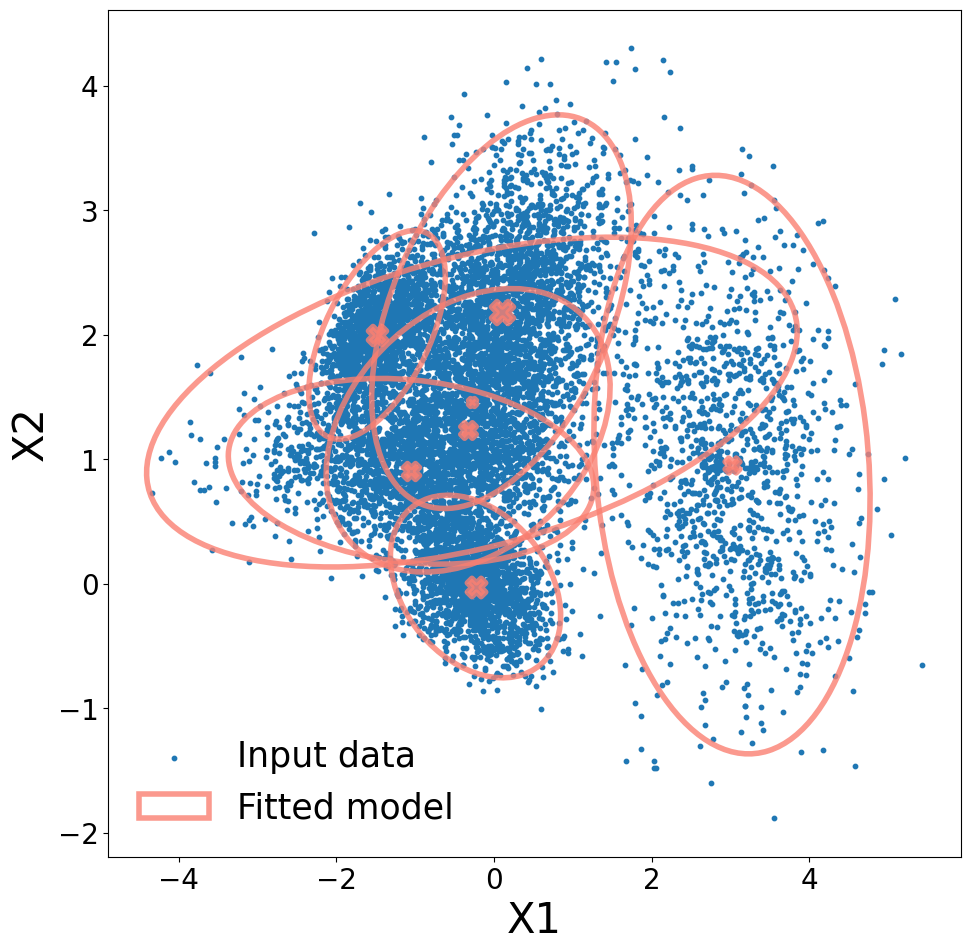

In [14]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

In this case, the fitter found a couple of extra components, but the final estimate of MI is still consistent with the ground truth, and the fit looks good. There is no "best" way to select the number of GMM components, so you should always ensure you look at the fitted density estimator and decide if it is good enough.

## The fit returns overlapping components, with MI very close to 0 nat

When you have a larger number of data points and your threshold is not small enough, you might observe the following: the fitter finds one or more components, but they are all overlapping and do not really describe the data well. This is a combination of two effects: the random initialization gets stuck in a local optimum, and the threshold on each fit is not small enough. This is a [known limitation of GMMs](https://github.com/pmelchior/pygmmis/issues/18), which is easily fixed. In the following example, we increase the number of points and keep the fit threshold to 1e-3.

In [15]:
X = sample_gmm(1e5, true_weights, true_means, true_covariances, seed=13)

MI_mean, MI_std, k, fit = estimate(X, 'MI', protocol='sequential',
                                   max_components=50, threshold_fit=1e-3,
                                   return_k=True, return_fit=True)
print(f'Estimated MI: {MI_mean:.4f} \\pm {MI_std:.4f} nat (k={k})')

Estimated MI: 0.0022 \pm 0.0003 nat (k=2)


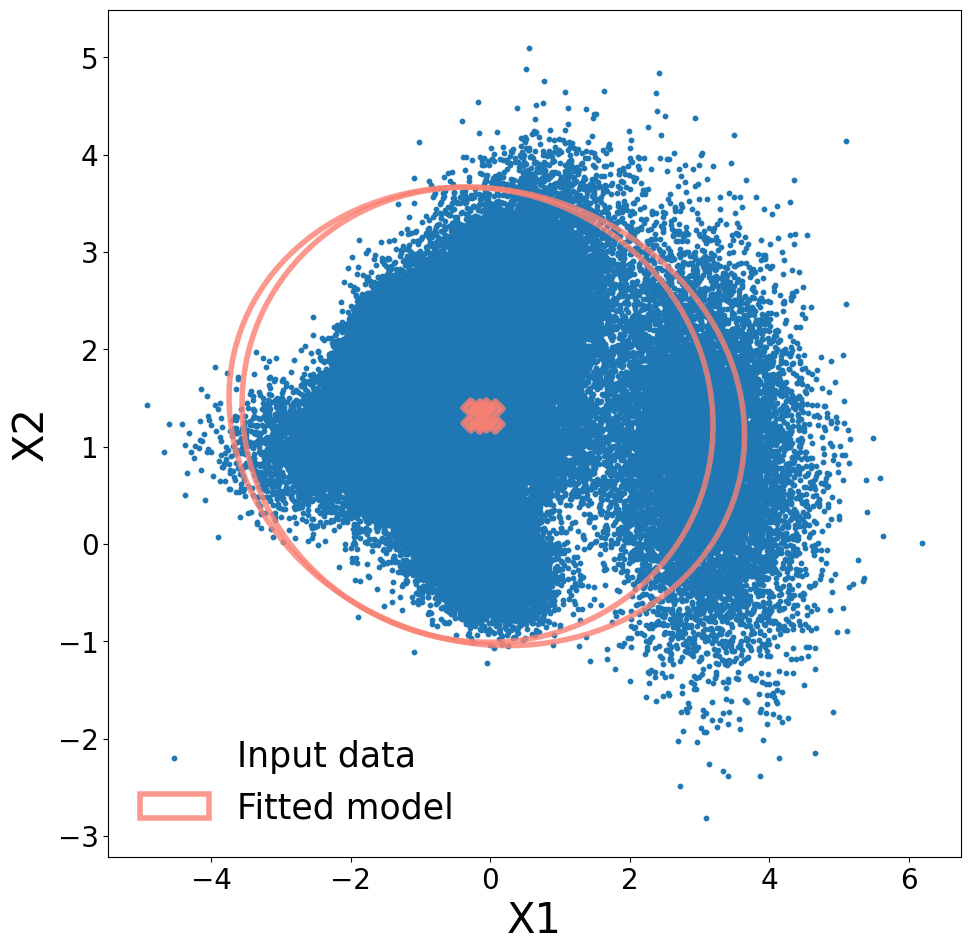

In [16]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

The fitter got clearly stuck: the components sit on top of each other and the MI estimate collapses towards 0. (At this point the original GMM-MI walkthrough also inspects the per-fit cross-validation loss curves; `gmm-mi-torch` runs all fits as one batched EM and does not currently record per-iteration loss curves, so we go straight to the fixes.) The fix can usually be obtained by lowering the threshold, or by changing the initialization type (or both):

In [17]:
# lower the threshold back to 1e-5, keeping the random initialization
MI_mean, MI_std, k, _ = estimate(X, 'MI', protocol='sequential',
                                 max_components=50,
                                 return_k=True, return_fit=True)
print(f'threshold_fit=1e-5, random init: '
      f'MI = {MI_mean:.4f} \\pm {MI_std:.4f} nat (k={k})')

threshold_fit=1e-5, random init: MI = 0.1829 \pm 0.0024 nat (k=5)


In [18]:
# or keep the loose threshold but switch to the k-means initialization
MI_mean, MI_std, k, _ = estimate(X, 'MI', protocol='sequential',
                                 max_components=50, threshold_fit=1e-3,
                                 init_type='kmeans',
                                 return_k=True, return_fit=True)
print(f'threshold_fit=1e-3, kmeans init: '
      f'MI = {MI_mean:.4f} \\pm {MI_std:.4f} nat (k={k})')

threshold_fit=1e-3, kmeans init: MI = 0.1834 \pm 0.0020 nat (k=5)


With the right initialization and a low-enough threshold, you should be able to fit your data, and check the actual convergence with the fitted-model and contour plots.

### However, a single initialization can still get stuck in a local optimum!

Consider the following example. We fit D5' with the known number of components (`fixed_components_number=5`) and a threshold that we have seen to be small enough for this problem; however, we only use 1 initialization and 2 folds. The data seed is also purposefully chosen so that this example will fail with the randomized $k$-means initialization (which kicks the $k$-means means around according to a user-specified `scale`). We ignore the bootstrap step too (`n_bootstrap=0`), and only perform one final fit, so that no MI uncertainty is returned. What happens is quite tricky.

In [19]:
X = sample_gmm(1e4, true_weights, true_means, true_covariances, seed=2)

MI_mean, _, fit = estimate(X, 'MI', fixed_components_number=5,
                           n_inits=1, n_folds=2, n_bootstrap=0,
                           init_type='randomized_kmeans', scale=5,
                           return_fit=True)
print(f'Estimated MI: {MI_mean:.4f} nat  (true MI: {true_MI:.4f} nat)')

Estimated MI: 0.1422 nat  (true MI: 0.1798 nat)


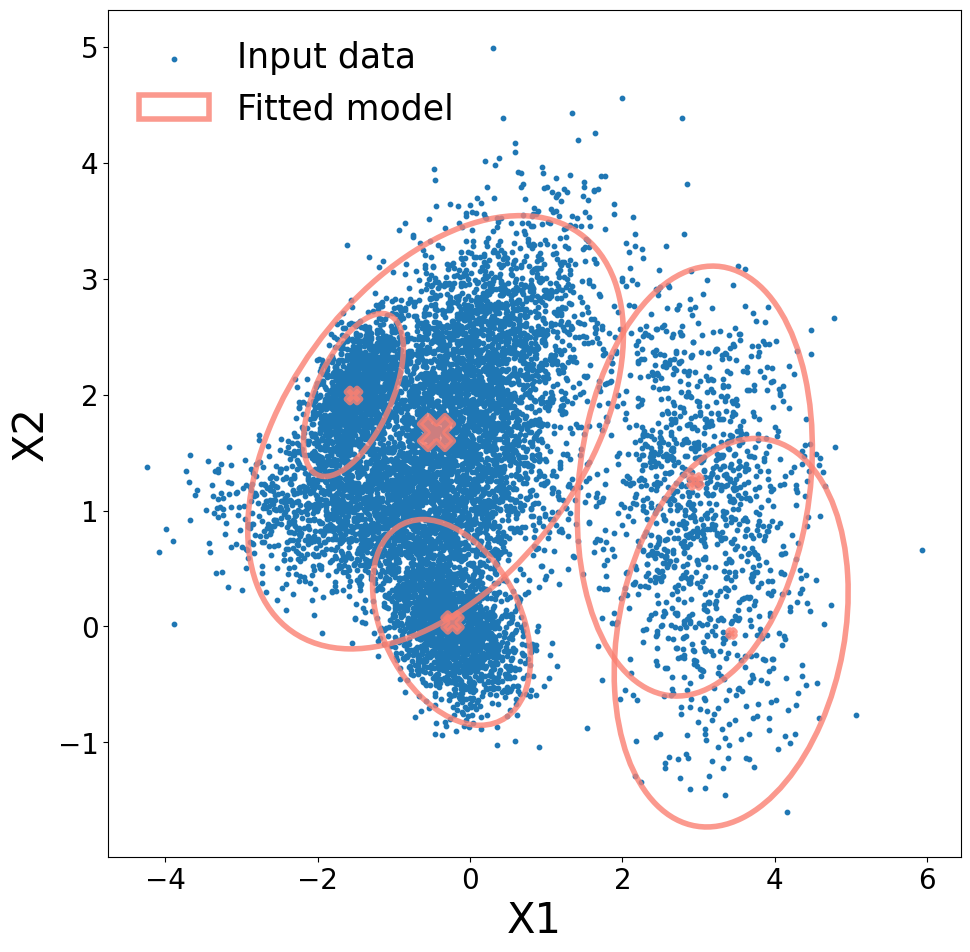

In [20]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

Despite using the right number of components, and having a low threshold, the fitter gets stuck in a local optimum: the fit is not awful, but the final value of MI returned is heavily biased. If you suspect this is happening to you, you can increase the number of initializations (we recommend never setting `n_inits` to 1, to avoid such cases):

In [21]:
MI_mean, _, fit = estimate(X, 'MI', fixed_components_number=5,
                           n_inits=2, n_folds=2, n_bootstrap=0,
                           init_type='randomized_kmeans', scale=5,
                           return_fit=True)
print(f'Estimated MI: {MI_mean:.4f} nat  (true MI: {true_MI:.4f} nat)')

Estimated MI: 0.1874 nat  (true MI: 0.1798 nat)


Alternatively, a different initialization type also works in this particular case.

In [22]:
MI_mean, _, fit = estimate(X, 'MI', fixed_components_number=5,
                           n_inits=1, n_folds=2, n_bootstrap=0,
                           init_type='kmeans',
                           return_fit=True)
print(f'Estimated MI: {MI_mean:.4f} nat  (true MI: {true_MI:.4f} nat)')

Estimated MI: 0.1875 nat  (true MI: 0.1798 nat)


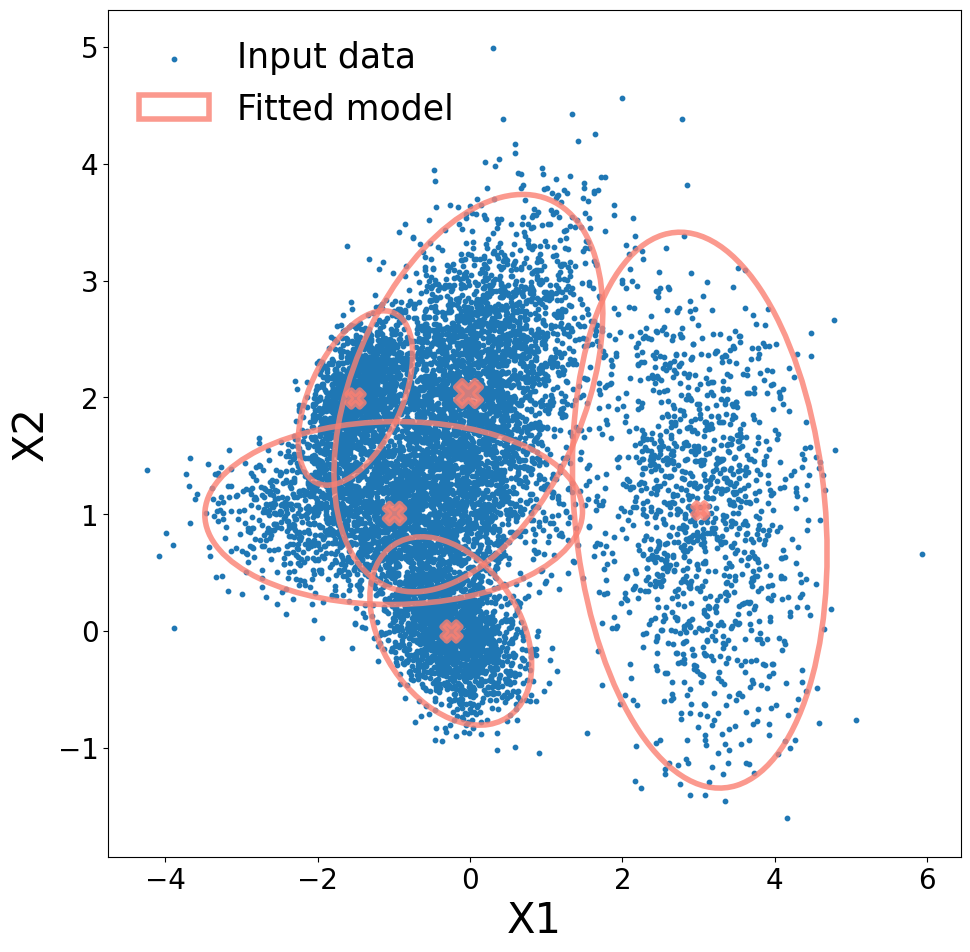

In [23]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

# Fitting data with hard boundaries

In general, the estimator can fit any dataset, as long as it is capable of estimating its density distribution. In the following example, we fit a particularly weird distribution, i.e. a square point cloud (each marginal is uniform). The hard boundaries of this dataset make a Gaussian mixture model not the appropriate tool to obtain a good density estimate; for this reason, we recommend against using GMM-based MI estimation on such data. Let's see one such example.

In [24]:
N = int(1e4)
X1 = rng.uniform(0, 1, N).reshape(-1, 1)
X2 = rng.uniform(-1, 0, N).reshape(-1, 1) + 1
X = np.concatenate((X1, X2), axis=1)

In [25]:
MI_mean, MI_std, k, fit = estimate(X, 'MI', protocol='sequential',
                                   max_components=50,
                                   return_k=True, return_fit=True)
print(f'Estimated MI: {MI_mean:.4f} \\pm {MI_std:.4f} nat (k={k})')

Estimated MI: 0.0001 \pm 0.0002 nat (k=1)


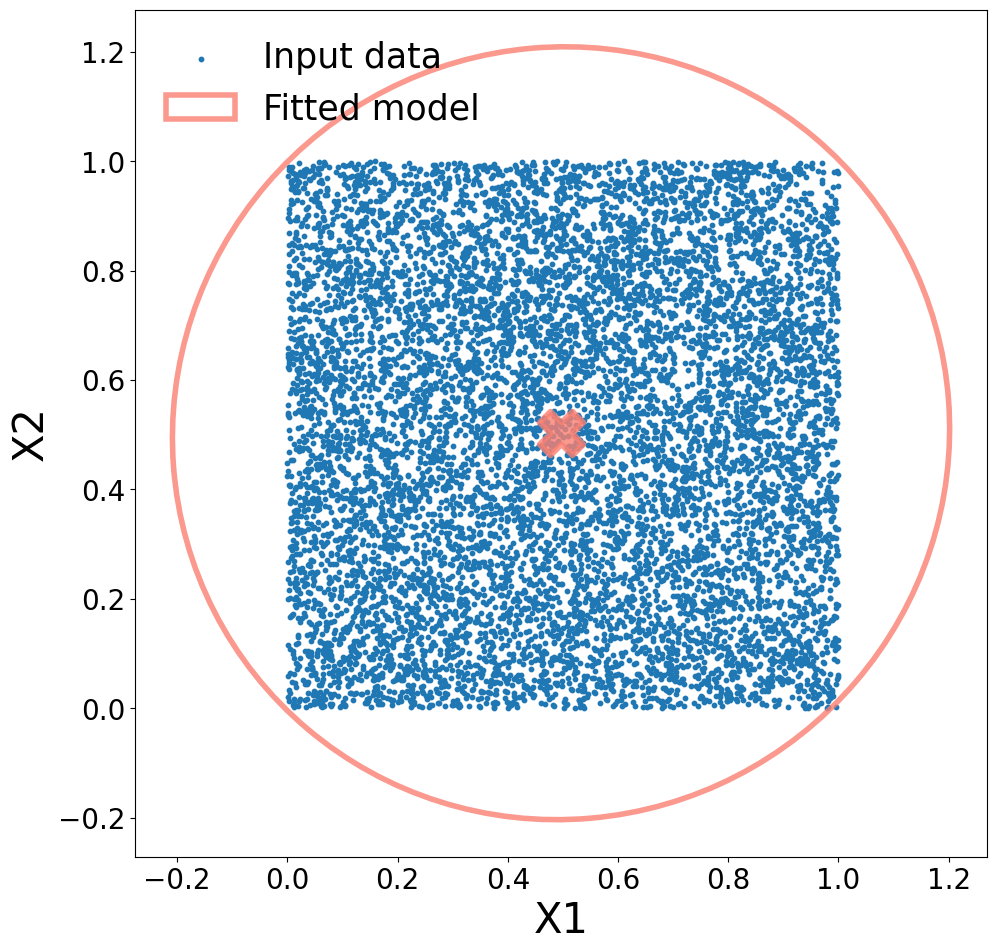

In [26]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

With the default random initialization, even with `threshold_fit=1e-5`, the fitter only finds one component, which, even if beautifully symmetric, does not represent a good density estimate. While the MI is consistent with 0 nat (the ground truth value in this case), the fit is poor. We get a better fit by changing the initialization type to e.g. `kmeans`; however, we set a low number of `max_components` so that the fit stops at some point.

In [27]:
MI_mean, MI_std, k, fit = estimate(X, 'MI', protocol='sequential',
                                   max_components=5, init_type='kmeans',
                                   return_k=True, return_fit=True)
print(f'Estimated MI: {MI_mean:.4f} \\pm {MI_std:.4f} nat (k={k})')

Estimated MI: 0.0163 \pm 0.0012 nat (k=5)


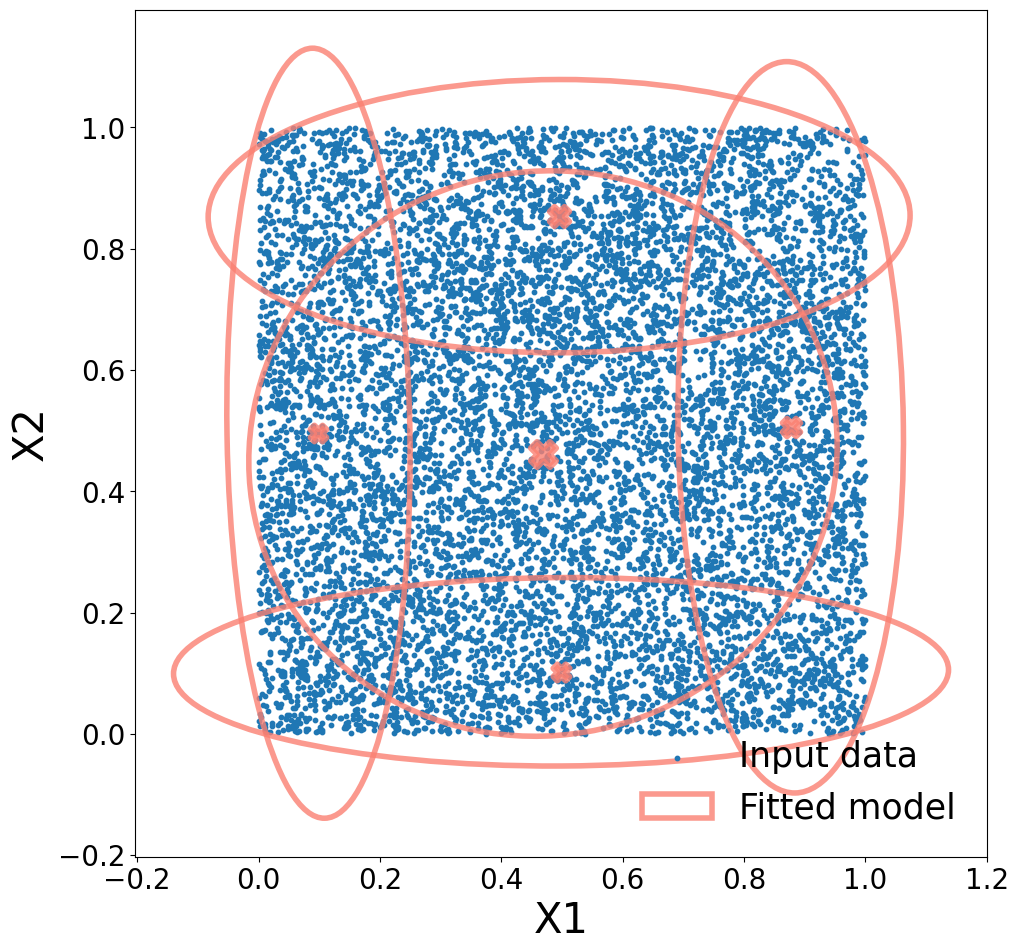

In [28]:
fig, ax = plt.subplots(1, 1, figsize=(11, 11))
ax.scatter(X[:, 0], X[:, 1], label='Input data', s=10)
ax = plot_gmm_contours(fit, ax=ax, color='salmon', alpha=0.8, linewidth=4,
                       fill=False, label='Fitted model')
ax.tick_params(axis='both', which='both', labelsize=20)
ax.set_xlabel('X1', fontsize=30)
ax.set_ylabel('X2', fontsize=30)
ax.legend(fontsize=25, frameon=False);

The fit has more features, but GMMs are not a good density estimator for this particular dataset; the final MI estimate is not consistent with the true value of 0 nat. In general, we do not recommend using GMM-based MI estimation on such data with hard boundaries!

In case you really need to work with such data, we recommend using the properties of MI to make your life easier. You can for example transform each marginal according to an inverse [sigmoid function](https://en.wikipedia.org/wiki/Sigmoid_function), which will allow you to avoid the hard boundaries, while maintaining the MI estimates unchanged.

In [29]:
X_t = X.copy()
# inverse sigmoid
X_t[:, 0] = np.log(X_t[:, 0] / (1 - X_t[:, 0]))
X_t[:, 1] = np.log(X_t[:, 1] / (1 - X_t[:, 1]))

MI_mean, MI_std, k = estimate(X_t, 'MI', protocol='sequential',
                              max_components=50, return_k=True)
print(f'Estimated MI: {MI_mean:.4f} \\pm {MI_std:.4f} nat (k={k})')

Estimated MI: 0.0020 \pm 0.0008 nat (k=5)


The estimate is now less than 3 standard deviations away from 0! `gmm-mi-torch` also has this trick built in: `preprocess='gaussianise'` maps each marginal through its ranks to a Gaussian shape (MI is invariant under monotonic transformations of the marginals), with no manual transformation needed. Tied values share their average rank, so each tied block lands on a single point of the probit scale; on heavily quantised or zero-inflated data the transformed marginal is therefore not Gaussian, and `gaussianise` raises a `RuntimeWarning` to say so:

In [30]:
MI_mean, MI_std, k = estimate(X, 'MI', protocol='sequential',
                              max_components=50, preprocess='gaussianise',
                              return_k=True)
print(f'Estimated MI: {MI_mean:.4f} \\pm {MI_std:.4f} nat (k={k})')

Estimated MI: 0.0001 \pm 0.0001 nat (k=1)


# Conditional mutual information

You can also compute the conditional mutual information between continuous variables, defined for three variables as:

$$I(X; Y \mid Z) = \int_{z \in Z} \int_{x \in X} \int_{y \in Y} p(x,y,z) \log \frac{p(z) p(x,y, z)}{p(x, z)p(y, z)} \ dx \ dy \ dz$$

where $p(x,y,z)$ is the joint probability density function of X, Y and Z. We provide an example below, for a simple multivariate Gaussian case. Note that you can calculate a generic conditional MI, i.e. $I(X; Y \mid Z_1, ..., Z_n)$: pass `quantity='cMI'` with an input array of shape `(n_samples, n_features)` whose first two columns are X and Y, and all remaining columns are the conditioning variables. To create such an array you can do something like:

```
X_tot = np.concatenate((x.reshape(-1, 1), y.reshape(-1, 1), z.reshape(-1, 1)), axis=1)
```

where the `x`, `y` and `z` arrays contain the samples of each variable.

In [31]:
# create simple mock trivariate Gaussian data
N = int(1e4)
mean = np.array([0, 0, 0])
cov = np.array([[1, 0.6, 0.4], [0.6, 1, 0.2], [0.4, 0.2, 1]])
rng = np.random.default_rng(0)
X = rng.multivariate_normal(mean, cov, N)  # has shape (N, 3)

cMI_mean, cMI_std, fit = estimate(X, 'cMI', max_components=5,
                                  return_fit=True)
print(f'Estimated conditional MI: {cMI_mean:.3f} \\pm {cMI_std:.3f} nat')

Estimated conditional MI: 0.194 \pm 0.006 nat


The true value of conditional MI in this case can be computed by splitting the integral above and using the known [differential entropy](https://en.wikipedia.org/wiki/Differential_entropy) formula for a multivariate Gaussian.

In [32]:
def differential_entropy_gaussian(cov):
    """Given a covariance matrix, compute the differential entropy
    of a multivariate Gaussian distribution.
    """
    d = cov.shape[0]
    prefac = 0.5 * d * np.log(2*np.pi*np.exp(1))
    determinant = 0.5 * np.log(np.linalg.det(cov))
    return prefac + determinant

In [33]:
pz = differential_entropy_gaussian(cov[2:, 2:])
pxyz = differential_entropy_gaussian(cov)
# we use a mask for the xz marginal
xz_c_mask = [[True, False, True],
             [False, False, False],
             [True, False, True]]
pxz = differential_entropy_gaussian(cov[xz_c_mask].reshape(2, 2))
# for the yz case, we can simply slice
pxy = differential_entropy_gaussian(cov[1:, 1:])
analytic_cmi = -pz - pxyz + pxz + pxy
# in pretty good agreement with the estimate returned above
print(f'Analytic conditional MI: {analytic_cmi:.3f} nat')

Analytic conditional MI: 0.204 nat


We can also check how good the GMM fit is by plotting the following contours.

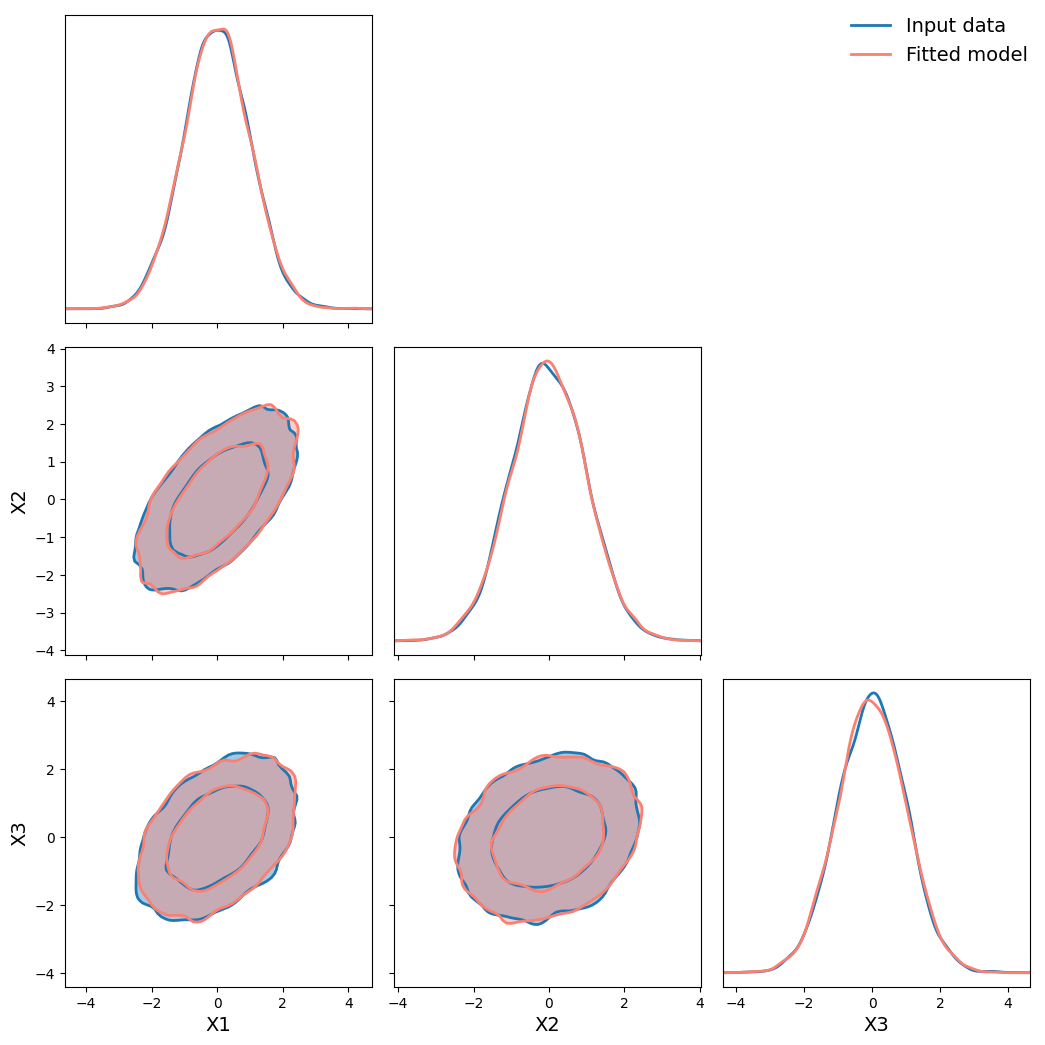

In [34]:
fig = plot_contours(X, fit.sample(len(X)),
                    parameters=['X1', 'X2', 'X3'])

# MI matrices

When you have more than two variables, the most useful summary is often the full grid of pairwise dependencies. Here we compute the pairwise MI matrix $I(X_i; X_j)$ and the conditional MI matrix $I(X_i; X_j \mid \mathrm{rest})$ for the trivariate Gaussian above, and visualise them with the annotated heatmap helpers (`create_heatmap`/`annotate_heatmap`, the same routines used for the MI matrices in the GMM-MI paper). For a Gaussian both quantities are analytic, so we can once more check the estimates. The diagonal (formally infinite) is left at 0.

In [35]:
labels = ['X1', 'X2', 'X3']
d = X.shape[1]
mi_grid, cmi_grid = np.zeros((d, d)), np.zeros((d, d))
for i in range(d):
    for j in range(i + 1, d):
        rest = [c for c in range(d) if c not in (i, j)]
        pair = X[:, [i, j] + rest]
        mi_grid[i, j] = mi_grid[j, i] = estimate(pair[:, :2], 'MI',
                                                 max_components=3)[0]
        cmi_grid[i, j] = cmi_grid[j, i] = estimate(pair, 'cMI',
                                                   max_components=3)[0]

# analytic counterparts, from the Gaussian differential entropy formula
h = differential_entropy_gaussian
sub = lambda rows: cov[np.ix_(rows, rows)]
mi_true, cmi_true = np.zeros((d, d)), np.zeros((d, d))
for i in range(d):
    for j in range(i + 1, d):
        rest = [c for c in range(d) if c not in (i, j)]
        mi_true[i, j] = mi_true[j, i] = \
            h(sub([i])) + h(sub([j])) - h(sub([i, j]))
        cmi_true[i, j] = cmi_true[j, i] = \
            h(sub([i] + rest)) + h(sub([j] + rest)) \
            - h(sub(rest)) - h(sub([i, j] + rest))
print('analytic MI grid (nat):\n', np.round(mi_true, 3))
print('analytic cMI grid (nat):\n', np.round(cmi_true, 3))

analytic MI grid (nat):
 [[0.    0.223 0.087]
 [0.223 0.    0.02 ]
 [0.087 0.02  0.   ]]
analytic cMI grid (nat):
 [[0.    0.204 0.068]
 [0.204 0.    0.001]
 [0.068 0.001 0.   ]]


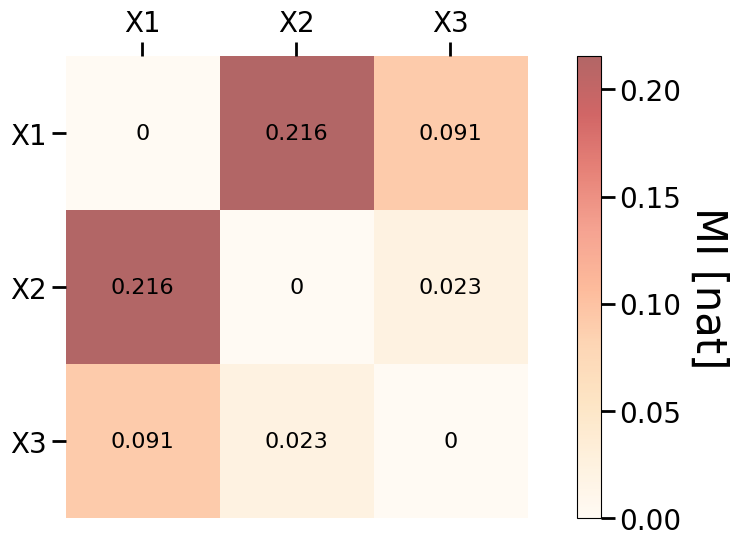

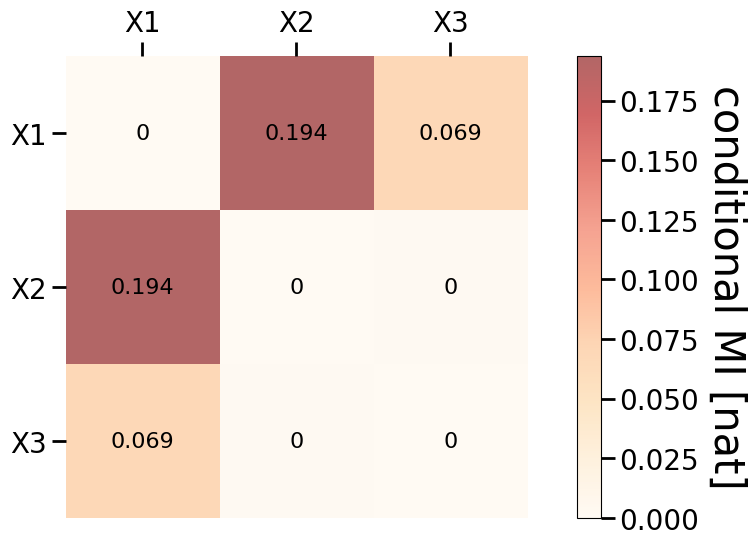

In [36]:
for grid, title in ((mi_grid, 'MI'), (cmi_grid, 'conditional MI')):
    fig, ax = plt.subplots(1, 1, figsize=(7, 6))
    im, cbar = create_heatmap(grid, labels, labels, fsize=20, ax=ax,
                              cmap='OrRd', alpha=0.6, vmin=0.0,
                              cbarlabel=f'{title} [nat]')
    annotate_heatmap(im, valfmt='{x:.3f}', fontsize=16)

Both grids agree with their analytic counterparts. Comparing the two also shows the effect of conditioning: for instance, $I(X_1; X_3)$ drops once $X_2$ is conditioned on, since part of that dependence is mediated by $X_2$, while $I(X_1; X_2 \mid X_3)$ stays close to its unconditioned value.

# Distribution of estimates over repeated datasets

The GMM-MI paper validates the bootstrap errorbars by comparing them against the scatter of the MI estimate over many independent realisations of the data. We can do the same here: draw 501 independent datasets from the $\rho=0.6$ bivariate Gaussian of the first example (the same number of realisations as the GMM-MI significance notebooks, which precompute and cache them; the torch port is fast enough to simply run them all in place), estimate MI on each, and look at the distribution of the estimates with the `histogram_estimates` helper (which also reports the mean, the error on the mean, and the significance of the mean with respect to 0). If the bootstrap errorbars are well calibrated, the average bootstrap $\sigma$ should match the scatter of the estimates across realisations.

In [37]:
mean, cov = np.array([0, 0]), np.array([[1, 0.6], [0.6, 1]])
analytic_MI = analytic_MI_gaussian(cov)

n_repeats = 501
means, stds = np.zeros(n_repeats), np.zeros(n_repeats)
for r in range(n_repeats):
    rng_r = np.random.default_rng(1000 + r)
    X_r = rng_r.multivariate_normal(mean, cov, 5000)
    means[r], stds[r] = estimate(X_r, 'MI', max_components=3, seed=r)

print(f'analytic MI:                 {analytic_MI:.4f} nat')
print(f'scatter of the estimates:    {means.std(ddof=1):.4f} nat')
print(f'average bootstrap sigma:     {stds.mean():.4f} nat')

analytic MI:                 0.2231 nat
scatter of the estimates:    0.0091 nat
average bootstrap sigma:     0.0087 nat


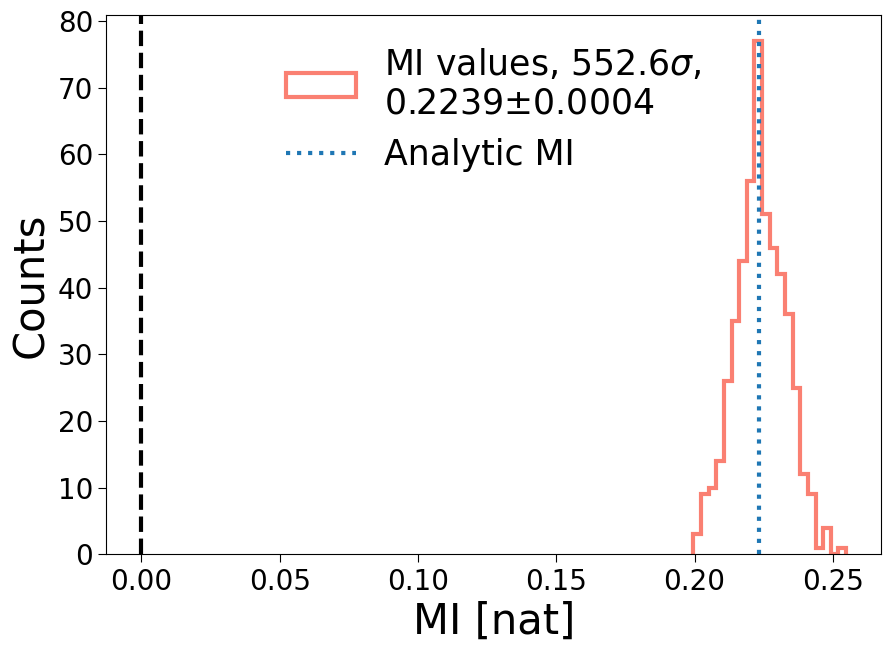

In [38]:
fig, ax = plt.subplots(1, 1, figsize=(10, 7))
histogram_estimates(means, ax=ax)
ax.axvline(analytic_MI, ls=':', lw=3, c='C0', label='Analytic MI')
ax.legend(fontsize=25, frameon=False);

The estimates scatter around the analytic value, and the average bootstrap $\sigma$ agrees well with the observed scatter across independent datasets - the errorbars mean what they claim to mean. (The repository's test suite includes an offline coverage-calibration test doing exactly this check quantitatively; see `tests/`.)

The histogram above looks at the raw MI values; the figure the GMM-MI paper actually uses for this validation is the histogram of the **standardized residuals**, $(\widehat{\mathrm{MI}} - \mathrm{MI}_\mathrm{true})/\sigma_\mathrm{bootstrap}$, compared against a standard normal, with the reduced $\chi^2$ reported. This is the stronger statement: it checks the errorbars realisation by realisation, not just their average size.

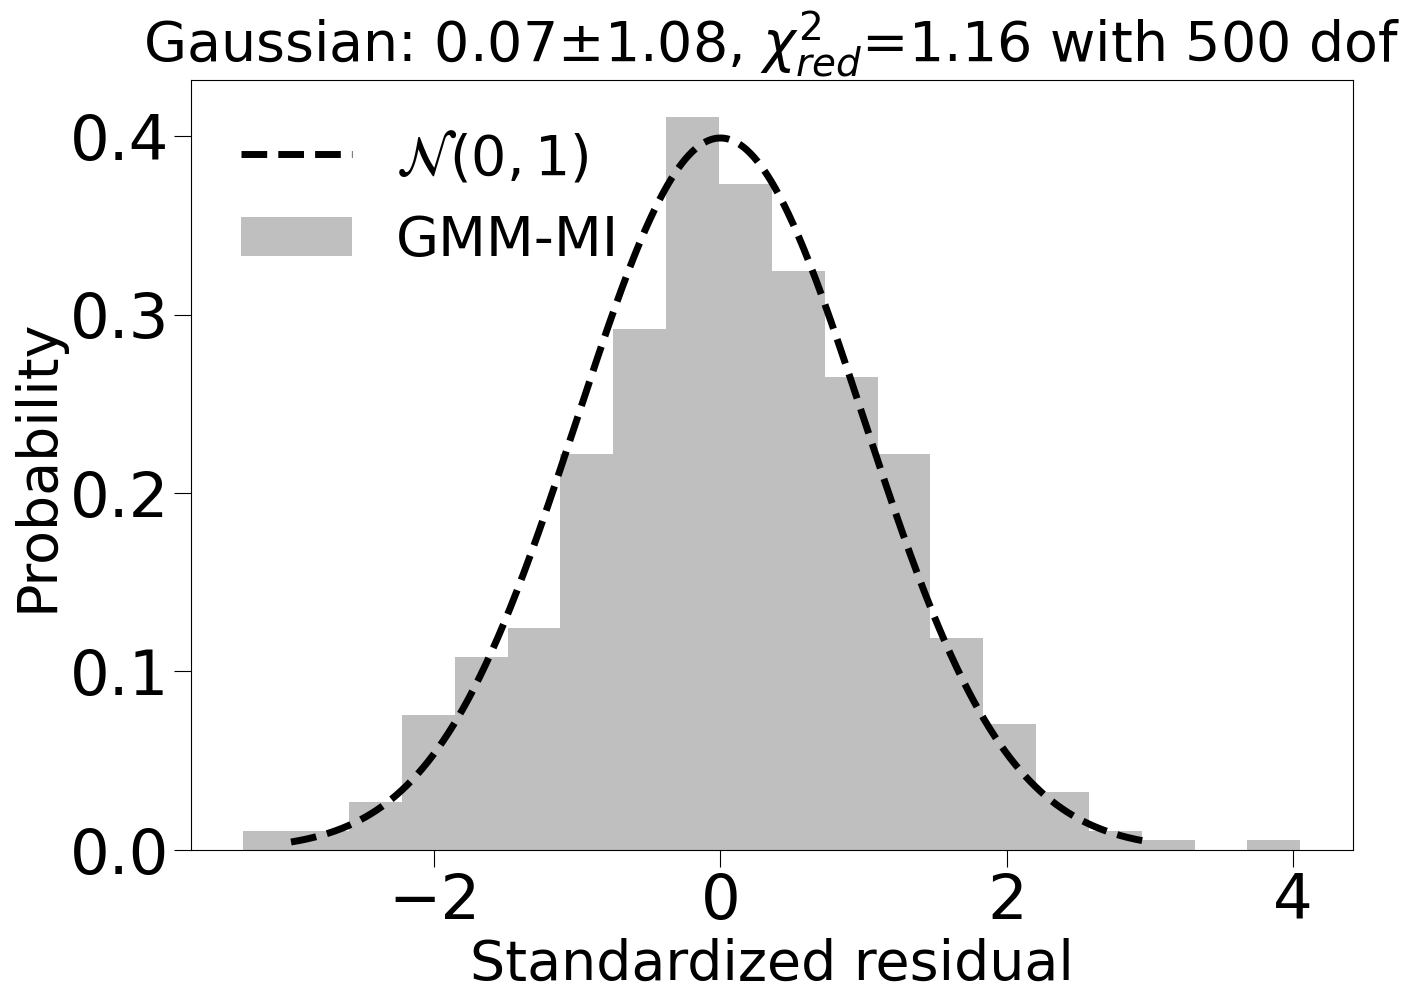

In [39]:
estimates = np.column_stack([means, stds])
biases, red_chi2, df = plot_bias_chi2_histogram(estimates, analytic=analytic_MI,
                                                ds='Gaussian', show_title=True,
                                                show_legend=True,
                                                labelfontsize=40, legendsize=40)

The standardized residuals follow the standard normal closely, with a reduced $\chi^2$ close to 1: the bootstrap errorbars are well calibrated realisation by realisation, underestimating the true scatter by only a few per cent. This reproduces the validation shown in the GMM-MI paper.

# Devices, precision and speed

The original GMM-MI is based on `sklearn`, where controlling the number of cores requires fiddling with OpenMP environment variables. `gmm-mi-torch` instead runs the whole procedure (all initializations, folds and bootstrap realizations) as one batched tensor computation, so parallelism is controlled through torch:

- on CPU, `torch.set_num_threads(n)` bounds the cores used;
- on a GPU, pass `device='cuda'`. On most GPUs you also want `dtype=torch.float32`; the full test suite passes at that precision. You do not need to tune anything else: the code works out how many fits to run at once from the memory the GPU has free, and backs off automatically if it runs out.

```python
MI_mean, MI_std = estimate(X, 'MI', device='cuda', dtype=torch.float32)
```

On an NVIDIA GB10 this is roughly 70 times faster than the sklearn-based GMM-MI for choosing the number of components and 80 times faster for the bootstrap (v0.2.1). If your dataset is so large that even a single fit does not fit in memory, the `n_chunk` argument processes the samples in pieces; see the README.

One `estimate` call keeps a whole GPU busy, so on a single GPU the fastest way through many pairs is a plain loop. If you have a node with several GPUs, run one worker process per GPU instead — the README's "Many pairs, many GPUs" section has a ready-made recipe (it must live in a script, not a notebook: worker processes cannot import functions defined in a notebook).


## Any other problems which are not covered here?
Help us make this package better! If you have trouble fitting your data with `gmm-mi-torch`, please raise an issue on this repository. For the original GMM-MI package, see [dpiras/GMM-MI](https://github.com/dpiras/GMM-MI) or contact [Davide Piras](mailto:dr.davide.piras@gmail.com).